<a href="https://colab.research.google.com/github/Sindyqc/Taller_3.ipynb/blob/main/Taller_Aprendizaje_No_Supervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:
iris = load_iris()
x = iris.data
y = iris.target

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
from google.colab import files
uploaded = files.upload()

Saving steam-200k.csv.zip to steam-200k.csv.zip


In [12]:
df=pd.read_csv("steam-200k.csv.zip")

In [13]:
df.head()

,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
0,151603712,The Elder Scrolls V Skyrim,play,273.0,0
1,151603712,Fallout 4,purchase,1.0,0
2,151603712,Fallout 4,play,87.0,0
3,151603712,Spore,purchase,1.0,0
4,151603712,Spore,play,14.9,0


In [14]:
df.shape

(199999, 5)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199999 entries, 0 to 199998
Data columns (total 5 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   151603712                   199999 non-null  int64  
 1   The Elder Scrolls V Skyrim  199999 non-null  object 
 2   purchase                    199999 non-null  object 
 3   1.0                         199999 non-null  float64
 4   0                           199999 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB


In [16]:
df.describe()

,151603712,1.0,0
count,1.999990e+05,199999.000000,199999.0
mean,1.036556e+08,17.874468,0.0
std,7.208084e+07,138.057292,0.0
min,5.250000e+03,0.100000,0.0
25%,4.738420e+07,1.000000,0.0
50%,8.691201e+07,1.000000,0.0
75%,1.542309e+08,1.300000,0.0
max,3.099031e+08,11754.000000,0.0


In [17]:
df.isnull().sum()


,0
151603712,0
The Elder Scrolls V Skyrim,0
purchase,0
1.0,0
0,0


In [18]:
df.duplicated().sum()

np.int64(707)

In [25]:
duplicados = df.duplicated().sum()
porcentaje = (duplicados / len(df)) * 100
print(f"El porcentaje de valores duplicados es: {porcentaje:.2f}%")

El porcentaje de valores duplicados es: 0.35%


In [19]:
df.columns = ['user_id', 'game', 'behavior', 'hours', 'columna_extra']

In [20]:
print ("tipos de variables del dasatet")
print (df.dtypes)

tipos de variables del dasatet
user_id            int64
game              object
behavior          object
hours            float64
columna_extra      int64
dtype: object


In [21]:
print ("\nInformacion general del dasatet:")
df.info()


Informacion general del dasatet:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199999 entries, 0 to 199998
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   user_id        199999 non-null  int64  
 1   game           199999 non-null  object 
 2   behavior       199999 non-null  object 
 3   hours          199999 non-null  float64
 4   columna_extra  199999 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB


In [26]:
df.isna().sum()

,0
user_id,0
game,0
behavior,0
hours,0
columna_extra,0


In [27]:
print("usuarios unicos:", df["user_id"].nunique())

usuarios unicos: 12393


In [28]:
print("Juegos únicos:", df["game"].nunique())

Juegos únicos: 5155


In [30]:
display(df["behavior"].value_counts().to_frame("cantidad"))

,cantidad
behavior,
purchase,129510
play,70489


In [32]:
display(df["hours"].describe())

,hours
count,199999.000000
mean,17.874468
std,138.057292
min,0.100000
25%,1.000000
50%,1.000000
75%,1.300000
max,11754.000000


In [34]:
compras = (
    df[df["behavior"] == "purchase"]
    .groupby("user_id")
    .agg(purchases=("game", "size"))
)

In [36]:
juego = (
    df[df["behavior"] == "play"]
    .groupby("user_id")
    .agg(
        total_play_hours=("hours", "sum"),
        games_played=("game", "nunique"),
        avg_hours_per_game=("hours", "mean")
    )
)

In [38]:
usuarios = compras.join(juego, how="outer").fillna(0)
usuarios["games_purchased"] = (
    df[df["behavior"] == "purchase"].groupby("user_id")["game"].nunique()
)

In [39]:
usuarios["games_purchased"] = usuarios["games_purchased"].fillna(0)

In [40]:
print("Usuarios para modelar:", len(usuarios))
display(usuarios.describe().round(2))

Usuarios para modelar: 12393


,purchases,total_play_hours,games_played,avg_hours_per_game,games_purchased
count,12393.00,12393.00,12393.00,12393.00,12393.00
mean,10.45,278.01,5.69,74.32,10.39
std,35.86,760.27,17.08,283.75,35.64
min,1.00,0.00,0.00,0.00,1.00
25%,1.00,1.30,1.00,1.10,1.00
50%,2.00,13.50,1.00,7.90,2.00
75%,6.00,155.60,3.00,39.00,6.00
max,1075.00,11754.00,498.00,11754.00,1068.00


In [41]:
from sklearn.preprocessing import StandardScaler

In [42]:
features = ["purchases", "total_play_hours", "games_played", "avg_hours_per_game"]
X = usuarios[features].copy()

In [44]:
import numpy as np

X_log = np.log1p(X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

In [45]:
print("Forma de la matriz de características:", X_scaled.shape)

Forma de la matriz de características: (12393, 4)


las variables agregadas se construyen con el fin de poder trbajar por unidad de analisis segun usuario y no por fila.

*   purchases : es el numero de registros de compra.
*   total_play_hours: es la suma de horas de juegos registradas.
*   games_played: es la cantidad de juegos con registro de juegos.
*   avg_houers_per_game: es el promedio de horas por cada juego jugado.

las variables estan muy sesgadas y contienen valores extremos. lo cual se aplica log1p, para poder reducir la unfluencia de usuarios con valores muy altos, y luego StandarScaler para que las variables tengan escalas comparables. toda ves que los valores faltantes de las agregaciones se reemplazan por cero, esto interpretando que no hay registro de esa actividad en el archivo.





In [46]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [47]:
resultados = []
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_scaled)
    silueta = silhouette_score(X_scaled, etiquetas, sample_size=min(3000, len(X_scaled)), random_state=42)
    resultados.append({"k": k, "silueta": silueta})

,k,silueta
0,2,0.490
1,3,0.477
2,4,0.420
3,5,0.412
4,6,0.426


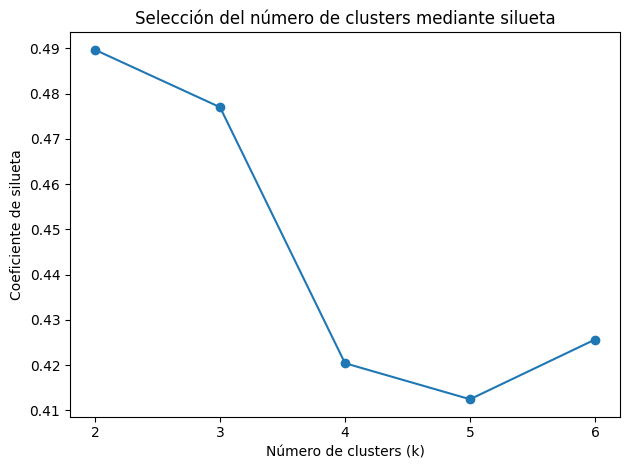

In [48]:
tabla_silueta = pd.DataFrame(resultados)
display(tabla_silueta.round(3))
tabla_silueta.plot(x="k", y="silueta", marker="o", legend=False)
plt.title("Selección del número de clusters mediante silueta")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(range(2, 7))
plt.tight_layout()
plt.show()

In [49]:
mejor_k = int(tabla_silueta.loc[tabla_silueta["silueta"].idxmax(), "k"])
print("Mejor k según silueta:", mejor_k)

Mejor k según silueta: 2


In [50]:
kmeans = KMeans(n_clusters=mejor_k, random_state=42, n_init=10)
usuarios["cluster"] = kmeans.fit_predict(X_scaled)

Justificacion de los algoritmo que se utilizo:

En la eleccion anterior, se empleo el algoritmo K-Means porque es sencillo de poder interpretar, lo cual permite asignar cada ususario a un segmento y ademas permite un buen funcionamineto con variables nemericas estanderizadas. su limitacion es que hay que elegir previamnete el numero de grupos y puede verse afectado por valores extremos; toda ves que la transformacion logaritmica reduce parcialmente ese problema.

para poder elegir k, se debe comparar el coeficiente de silueta  en varios valores.
ya que al calcularlo sobre todos los usuarios ouede ser costoso, se usa una muestra aleatoria fija para tal evaluacion, se selecciona el valor con mejor silueta y se revisa tambien si los grupos son interpretables.

Interpretación de los cluster

  • Qué caracteriza a los usuarios de este grupo?

  se logra hacer una comparacion en tamaño, compras, horas totales y cantidad de juegos jugados por segmentos.

    • Son jugadores ocasionales o frecuentes?
  hay de ambos, pero la mayor concentracion se encuentra en jugadores frecuentes.

    • Presentan comportamientos similares de compra?
  no, puesto que los jugadores ocacionales realizan una compra aproximada a la mediana, en cambio los jugadores frecuentes realizan un aproximado de 28 compras a la mediana.

    • Qué diferencias existen entre los clusters?
  los clusters decriben patrones de actividad dentro de un archivo, y no necesariamente todo el comportamiento real de los usuarios.

Asigna un nombre representativo a cada segmento.
Ejemplo:

    • Jugadores Casual: usuarios ocasionales

    • Coleccionistas : usuarios comprometidos

    • Usuarios Muy Activos : usuarios intensivos

    • Compradores Frecuentes : usuarios impulsivos.




Recomendaciones de negocio
Con base en los segmentos encontrados.

    • la estrategia de marketing que se implementaría para cada grupo seria:
   

1.   aumentar la participacion de los jugadores con promosiones recomendadas.
2.   realizar descuentos de bienvenidas en juegos seleccionados.

  
    • el tipo de promociones que recibiría cada segmento seria:


1.   ofertas economicas por tiempos limitados.
2.   cupones para la primera compra de un nuevo genero de videojuegos.
3.   descuentos en niveles y contenidos adicionales.
4.   ofertas exclusivas en paquetes de juegos.
5.   ofertas en accesos anticipados a promosiones.
6.   regalos y beneficios por fidelizacion.


    • los usuarios a priorizar para campañas de fidelización seria:


*   usuarios intensivos y compradores frecuentes.
*   usuarios coleccionistas.

Información adicional que sería útil para mejorar la segmentación:

identificar usuarios inactivos y con posibles abandonos con las fechas de su ultima actividad.

ralizar un historial de compras y precios con la finalidad de medir gastos reales y asi poder distinguir compradores con alto valor.

diferencias jugadores o usuarios habituales, de los usuarios que juegan eventualmente.